
O faturamento total foi: R$85400

O faturamento de dezembro/2025 foi: R$55150

O faturamento de janeiro/2026 foi: R$30250




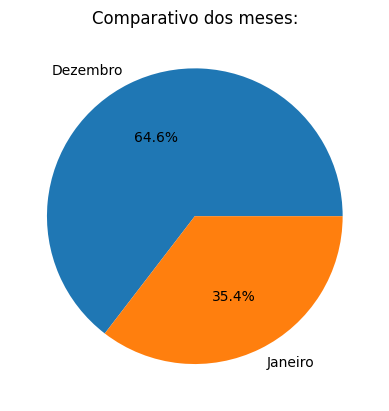


A categoria mais vendida foi: Games 
E rendeu: R$18000

A categoria menos vendida foi: Acessórios 
E rendeu: R$6200




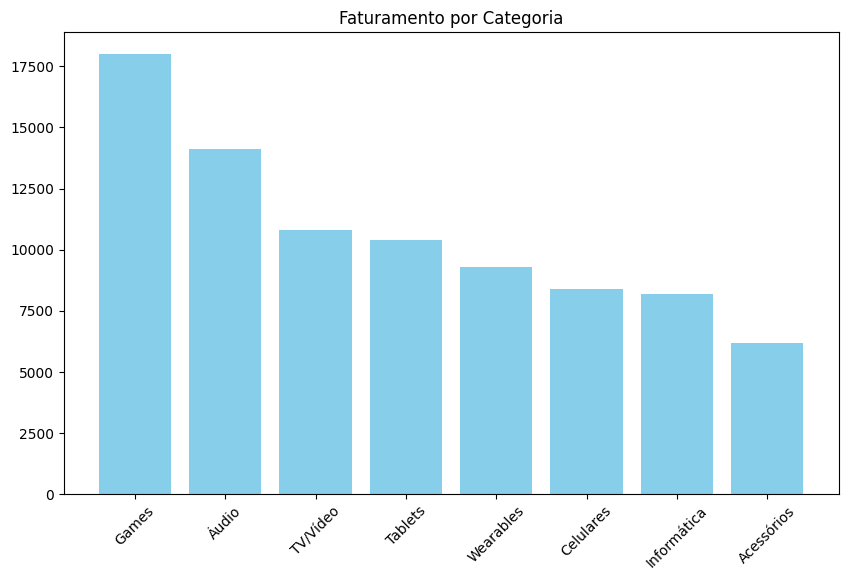


A venda média por dia foi: R$7763.64

O dia de maior venda foi 2025-12-20 00:00:00, onde foram vendidos R$18000

O dia de menor venda foi 2026-01-25 00:00:00, onde foram vendidos R$2700

O produto mais caro vendido foi: Smart TV 55" LG OLED. Que custa: R$5400

O produto mais barato vendido foi: Carregador Portátil 20.000mAh. Que custa: R$180

O Produto mais vendido foi: Carregador Portátil 20.000mAh. 
Enquanto o menos vendido foi: Notebook Dell Inspiron.


Relatório gerado: Relatorio_Analise_Vendas_2026-05-11_CarlosEduardo.docx


In [8]:
#Importando as bibliotecas necessárias para execução da análise
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xlrd
import openpyxl

#Bibliotecas para criação do relatório final
!pip install python-docx

from docx import Document
from docx.shared import Inches
from datetime import datetime

#Leitura e trabalhos iniciais com a tabela
vendas_geral = pd.read_excel('vendas_1.xlsx', engine='openpyxl')
vendas_geral['Data'] = pd.to_datetime(vendas_geral['Data'])
vendas_geral['Mês'] = vendas_geral['Data'].dt.strftime('%Y-%m')

#Faturamento
faturamento_total = vendas_geral['Total'].sum()
print(f'\nO faturamento total foi: R${faturamento_total}')
faturamento_mes_12 = vendas_geral[vendas_geral['Mês'] == '2025-12']['Total'].sum()
print(f'\nO faturamento de dezembro/2025 foi: R${faturamento_mes_12}')
faturamento_mes_1 = vendas_geral[vendas_geral['Mês'] == '2026-01']['Total'].sum()
print(f'\nO faturamento de janeiro/2026 foi: R${faturamento_mes_1}')

#Gráfico do Faturamento
print('\n')
eixo=np.array([faturamento_mes_12, faturamento_mes_1])
labels =['Dezembro' , 'Janeiro']
plt.title("Comparativo dos meses:")
plt.pie(eixo, labels=labels, autopct='%1.1f%%')
plt.savefig('grafico_faturamento.png')
plt.show()

#Vendas por categoria
vendas_categoria = vendas_geral.groupby('Categoria')['Total'].sum().sort_values(ascending=False)
categoria_mais_vendida = vendas_categoria.idxmax()
valor_mais_vendida = vendas_categoria.max()
print(f'\nA categoria mais vendida foi: {categoria_mais_vendida} \nE rendeu: R${valor_mais_vendida}')
categoria_menos_vendida = vendas_categoria.idxmin()
valor_menos_vendida = vendas_categoria.min()
print(f'\nA categoria menos vendida foi: {categoria_menos_vendida} \nE rendeu: R${valor_menos_vendida}')

#Gráfico das Vendas por categoria
print('\n')
eixoX = vendas_categoria.index.values
eixoY = vendas_categoria.values
plt.figure(figsize=(10, 6))
plt.bar(eixoX, eixoY, color='skyblue')
plt.title('Faturamento por Categoria')
plt.xticks(rotation=45)
plt.savefig('grafico_categorias.png')
plt.show()

#Análises adicionais
dias = vendas_geral['Data'].nunique()
media_diaria = faturamento_total/dias
print(f'\nA venda média por dia foi: R${media_diaria:.2f}')

dia_maior_venda = vendas_geral.groupby('Data')['Total'].sum().idxmax()
valor_dia_maior = vendas_geral.groupby('Data')['Total'].sum().max()
print(f'\nO dia de maior venda foi {dia_maior_venda}, onde foram vendidos R${valor_dia_maior}')
dia_menor_venda = vendas_geral.groupby('Data')['Total'].sum().idxmin()
valor_dia_menor = vendas_geral.groupby('Data')['Total'].sum().min()
print(f'\nO dia de menor venda foi {dia_menor_venda}, onde foram vendidos R${valor_dia_menor}')

produto_mais_caro = vendas_geral.groupby('Produto')['Valor Unitário'].sum().idxmax()
valor_produto_caro = vendas_geral.groupby('Produto')['Valor Unitário'].sum().max()
print(f'\nO produto mais caro vendido foi: {produto_mais_caro}. Que custa: R${valor_produto_caro}')
produto_mais_barato = vendas_geral.groupby('Produto')['Valor Unitário'].sum().idxmin()
valor_produto_barato = vendas_geral.groupby('Produto')['Valor Unitário'].sum().min()
print(f'\nO produto mais barato vendido foi: {produto_mais_barato}. Que custa: R${valor_produto_barato}')

produto_mais_vendido = vendas_geral.groupby('Produto')['Quantidade'].sum().idxmax()
produto_menos_vendido = vendas_geral.groupby('Produto')['Quantidade'].sum().idxmin()
print(f'\nO Produto mais vendido foi: {produto_mais_vendido}. \nEnquanto o menos vendido foi: {produto_menos_vendido}.')





#Relatório Final
# Introdução
documento = Document()
documento.add_heading('Relatório de Análise de Vendas - TechStore', 0)
documento.add_heading('1. Introdução', level=1)
documento.add_paragraph(
    'Este relatório apresenta uma análise das vendas realizadas pela loja TechStore, '
    'com o objetivo de identificar tendências, produtos mais e menos vendidos, '
    'e fornecer insights para estratégias futuras.'
)

# Faturamento
documento.add_heading('2. Faturamento', level=1)
documento.add_paragraph(
    'Conseguimos enxergar as tendencias de faturamento através do seguinte gráfico:'
)
documento.add_picture('grafico_faturamento.png', width=Inches(6))
documento.add_paragraph(
    'Nele, é possível notar o impacto positivo que as vendas de dezembro têm, quase dobrando com relação a janeiro, uma tendência esperada.'
    'É interessante ressaltar, também, que, analisando as vendas dia-a-dia e correlacionando as quantidades vendidas com os valores vendidos,'
    'a venda diária em janeiro é menor em valores, mas superior em quantidades. Isso mostra uma procura maior por itens mais acessíveis,'
    'e uma queda do ticket médio por compra.'
)

# Vendas por categoria
documento.add_heading('3. Vendas por categoria', level=1)
documento.add_paragraph(
    'O gráfico a seguir ordena as categorias por ordem de vendas e nos mostra detalhes interessantes:'
)
documento.add_picture('grafico_categorias.png', width=Inches(6))
documento.add_paragraph(
    'Quase como uma reafirmação do abordado no tópico anteiror, é possível notar que as 3 categorias que mais venderam'
    ' foram especialmente comercializadas no mês 12. Além disso, são categorias cujas vendas unitárias ficam aquem de outras, '
    'ainda assim, pelo alto valor agregado dão um retorno significativo para a loja.'
)

# Análises adicionais
documento.add_heading('4. Análises adicionais', level=1)
documento.add_paragraph(
    'Vendas por dia:'
)
documento.add_paragraph(
    'Avaliando as vendas por dia, podemos avaliar 2 aspectos diferentes:'
    '\n1 - Média por dia: Na média, foram vendidos R$7763,00 por dia. Chama a atenção que dos 11 dias registrados, '
    '6 apresentaram valores superiores em vendas, reforçando uma tendência alta em superar essa métrica nos próximos dias.'
    '\n2 - Dias de maior e menor venda: 20/12 foi o dia em que foi registrada o maior faturamento (R$18000,00). A data em questão '
    'chama a atenção por ser muito próxima ao natal, além de o dia registrar uma saída relevante de itens da categoria "Games".'
    '\nJá o dia de menor venda foi 25/01, onde foram comercializados apenas R$2700,00, tudo em Carregadores portáteis. Curiosamente, '
    'apesar de registrar a menor venda em valor, foi o dia com a maior saída em números de itens, além disso, o produto em questão é '
    'o de menor valor agregado no portfólio.'
)
documento.add_paragraph(
    'Produtos:'
)
documento.add_paragraph(
    'Os produtos, se analisados isoladamente, também nos mostram valores interessantes e algumas tendências.'
    'Para começar o produto mais caro vendido (Smart TV 55" LG OLED), foi comercializada no mês de dezembro, '
    'enquanto o mais barato (o já citado Carregador Portátil), no mês de janeiro.'
    ' Essas informações casam com as analises anteriores feitas, que indiam uma queda no ticket médio entre dezembro-janeiro, '
    'além da queda do valor agregrado dos produtos vendidos.'
    '\nOutro ponto interessante é que o produto mais barato foi, também, o mais vendido em unidades totais (18), algo esperado.'
    '   Porém, o menos vendido (Notebook Dell Inspiron), não é o mais caro, além de estar entre os tantos comercializados em dezembro, '
    'destoando um pouco da média do mês.'
)

# Conclusão
documento.add_heading('5. Conclusão', level=1)
documento.add_paragraph(
    'Avaliando de maneira geral os dados informados e o trabalho em cima deles, é possível destacar algumas coisas importantes:'
)
documento.add_paragraph(
    '\nPrimeiro, existe uma queda natural (e, de certa maneira, esperada), nos resultados de janeiro.'
    ' É importante que nos próximos meses os responsáveis pela loja estejam atentos em maximizar o ticket médio das vendas e, '
    'também, renovar os estoques com os produtos e tendências que acompanham o novo ano. '
    '\nEm seguida, fica a recomendação de focar em divulgação e promocões em produtos mais baratos, mas que sejam considerados '
    '"essenciais" para o consumidor da loja. Nos meses iniciais de um ano, com o acúmulo natural de contas e dívidas, '
    'é esperado que os clientes foquem menos em itens "luxuosos" e mais em coisas básicas.'
)

data_atual = datetime.now().strftime('%Y-%m-%d')
nome_arquivo = f'Relatorio_Analise_Vendas_{data_atual}_CarlosEduardo.docx'
documento.save(nome_arquivo)
print('\n')
print(f'Relatório gerado: {nome_arquivo}')